First few rows of the dataset:


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


Dataset shape: (891, 15)

Column details:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    object  
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    object  
 8   class        891 non-null    category
 9   who          891 non-null    object  
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    object  
 13  alive        891 non-null    object  
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), object(5)
memory usage: 80.7+ KB

Basic statistics:


,survived,pclass,age,sibsp,parch,fare
count,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200



Missing values in each column:
survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64

Duplicate rows: 116

Missing values after cleaning:
survived       0
pclass         0
sex            0
age            0
sibsp          0
parch          0
fare           0
embarked       0
class          0
who            0
adult_male     0
embark_town    0
alive          0
alone          0
dtype: int64

Duplicate rows after cleaning: 6

Cleaned dataset:


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,Southampton,no,True


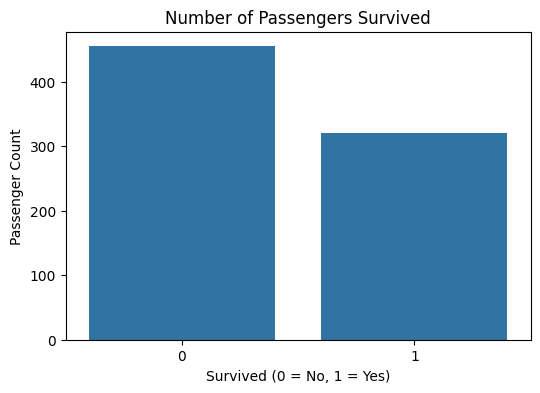

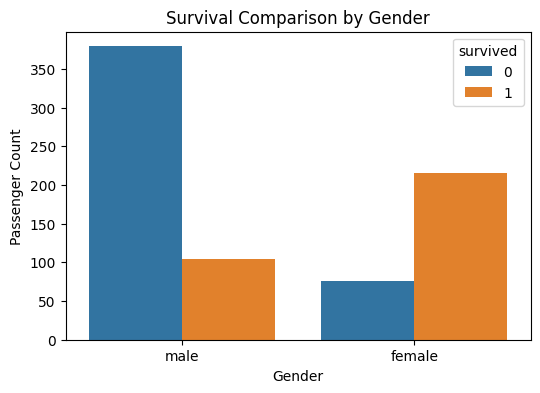

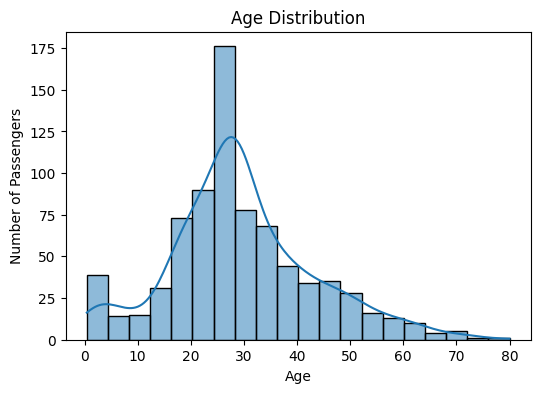

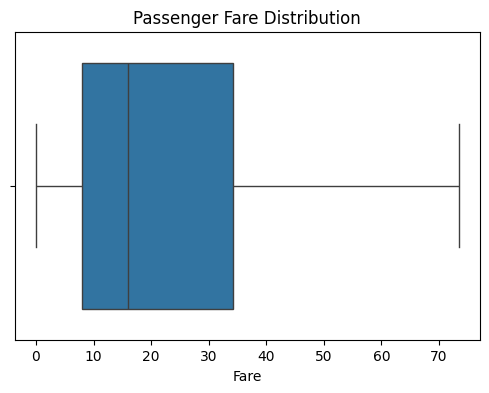


Data cleaning and visualization completed!
Cleaned file saved successfully.


In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Loading the Titanic dataset
data = sns.load_dataset('titanic')

print("First few rows of the dataset:")
display(data.head())

# Checking the dataset
print("Dataset shape:", data.shape)
print("\nColumn details:")
data.info()

print("\nBasic statistics:")
display(data.describe())

# Finding missing values
print("\nMissing values in each column:")
print(data.isnull().sum())

# Filling missing age values with the average middle value
data['age'] = data['age'].fillna(data['age'].median())

# Filling missing location details with the most common value
data['embarked'] = data['embarked'].fillna(data['embarked'].mode()[0])
data['embark_town'] = data['embark_town'].fillna(
    data['embark_town'].mode()[0]
)

# Removing the deck column as most of its values are missing
data = data.drop('deck', axis=1)

# Removing repeated rows
print("\nDuplicate rows:", data.duplicated().sum())
data = data.drop_duplicates()

# Checking and handling unusual fare values
q1 = data['fare'].quantile(0.25)
q3 = data['fare'].quantile(0.75)
iqr = q3 - q1

min_value = q1 - 1.5 * iqr
max_value = q3 + 1.5 * iqr

data['fare'] = data['fare'].clip(min_value, max_value)

# Checking the cleaned data
print("\nMissing values after cleaning:")
print(data.isnull().sum())

print("\nDuplicate rows after cleaning:", data.duplicated().sum())

print("\nCleaned dataset:")
display(data.head())

# Visualizing passenger survival
plt.figure(figsize=(6, 4))
sns.countplot(data=data, x='survived')
plt.title('Number of Passengers Survived')
plt.xlabel('Survived (0 = No, 1 = Yes)')
plt.ylabel('Passenger Count')
plt.show()

# Comparing survival based on gender
plt.figure(figsize=(6, 4))
sns.countplot(data=data, x='sex', hue='survived')
plt.title('Survival Comparison by Gender')
plt.xlabel('Gender')
plt.ylabel('Passenger Count')
plt.show()

# Understanding passenger age distribution
plt.figure(figsize=(6, 4))
sns.histplot(data['age'], bins=20, kde=True)
plt.title('Age Distribution')
plt.xlabel('Age')
plt.ylabel('Number of Passengers')
plt.show()

# Checking fare values after cleaning
plt.figure(figsize=(6, 4))
sns.boxplot(x=data['fare'])
plt.title('Passenger Fare Distribution')
plt.xlabel('Fare')
plt.show()

# Saving the cleaned data
data.to_csv('cleaned_titanic.csv', index=False)

print("\nData cleaning and visualization completed!")
print("Cleaned file saved successfully.")
